# 猫狗图片分类 · 主流程

一个 notebook 跑完 **训练 → 预测 → 评估 → 特征可视化**。

**省钱省时间的配置**：训练集每类抽 150 张、验证集每类 30 张，图片缩到 128×128，用 **ResNet18 迁移学习**只训 8 个 epoch。CPU 上 2-3 分钟跑完（首次运行会自动下载约 45MB 预训练权重），有 GPU 会自动用上。

> **迁移学习**：直接拿来别人在 ImageNet 上预训练好的网络，只换最后一层再微调。数据不多也能到 85%+，是实战里最常用的做法。

复用了项目里的 `model.py`，数据来自 `download_data.py` 下载的 `data/` 目录。

## 1. 环境准备

In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image

# 中文字体（Windows / 大部分 Linux 可用）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'WenQuanYi Zen Hei', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('设备:', device, '| PyTorch:', torch.__version__)
print('当前目录:', os.getcwd())

设备: cpu | PyTorch: 2.14.1+cpu
当前目录: D:\github_project\cat_dog_classifier


## 2. 加载数据（抽样控制成本）

`data/train` 每类有 500 张、`data/val` 每类 100 张。这里每类只抽 `train 150 / val 30`，几分钟内就能跑完；想跑全量把 `n_per_class` 调大即可。

In [2]:
from model import create_model

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

transform = transforms.Compose([
    transforms.Resize((128, 128)),  # 小尺寸，训练更快
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

full_train = datasets.ImageFolder('data/train', transform=transform)
full_val = datasets.ImageFolder('data/val', transform=val_transform)
classes = full_train.classes


def sample_per_class(dataset, n_per_class, seed=42):
    """每个类别随机抽 n_per_class 张。"""
    idx = []
    for cls in range(len(dataset.classes)):
        cls_idx = [i for i, (_, label) in enumerate(dataset.samples) if label == cls]
        random.Random(seed).shuffle(cls_idx)
        idx.extend(cls_idx[:n_per_class])
    return Subset(dataset, idx)


train_set = sample_per_class(full_train, 150)
val_set = sample_per_class(full_val, 30)
print('类别:', classes)
print(f'训练集: {len(train_set)} 张（每类 150）  验证集: {len(val_set)} 张（每类 30）')

类别: ['cat', 'dog']
训练集: 300 张（每类 150）  验证集: 60 张（每类 30）


### 看一眼数据长什么样

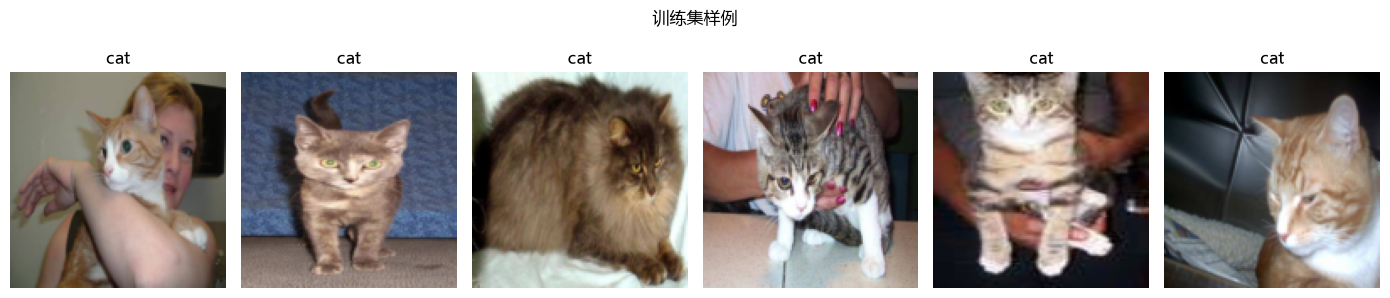

In [3]:
def denorm(t):
    t = t.clone()
    for c in range(3):
        t[c] = t[c] * STD[c] + MEAN[c]
    return t.clamp(0, 1)


fig, axes = plt.subplots(1, 6, figsize=(14, 3.2))
for ax, i in zip(axes, range(6)):
    img, label = train_set[i]
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ax.set_title(classes[label])
    ax.axis('off')
plt.suptitle('训练集样例')
plt.tight_layout()
plt.show()

## 3. 训练（ResNet18 迁移学习，8 个 epoch）

In [4]:
train_loader = DataLoader(train_set, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False, num_workers=0)

model = create_model('resnet18', num_classes=2).to(device)  # 预训练权重首次运行自动下载
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 8
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}


def run_one_epoch(loader, model, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = correct = total = 0.0
    with torch.set_grad_enabled(is_train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_one_epoch(train_loader, model, criterion, optimizer)
    va_loss, va_acc = run_one_epoch(val_loader, model, criterion)
    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(va_loss)
    history['val_acc'].append(va_acc)
    print(f'epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
          f'val loss {va_loss:.4f} acc {va_acc:.4f}')

epoch  1/8 | train loss 0.7630 acc 0.7500 | val loss 13.4557 acc 0.5500


epoch  2/8 | train loss 0.3717 acc 0.8600 | val loss 1.5520 acc 0.7833


epoch  3/8 | train loss 0.2137 acc 0.9000 | val loss 0.4476 acc 0.8500


epoch  4/8 | train loss 0.1628 acc 0.9433 | val loss 0.6591 acc 0.7500


epoch  5/8 | train loss 0.1044 acc 0.9633 | val loss 0.5103 acc 0.8333


epoch  6/8 | train loss 0.0982 acc 0.9600 | val loss 0.8465 acc 0.7833


epoch  7/8 | train loss 0.1293 acc 0.9567 | val loss 0.8178 acc 0.7667


epoch  8/8 | train loss 0.0890 acc 0.9733 | val loss 0.4206 acc 0.8500


### 训练曲线

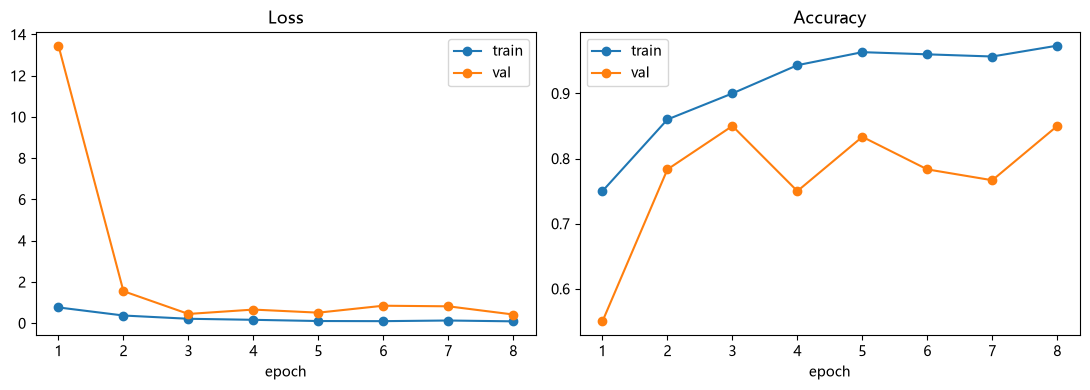

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ep = range(1, epochs + 1)
axes[0].plot(ep, history['train_loss'], 'o-', label='train')
axes[0].plot(ep, history['val_loss'], 'o-', label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(ep, history['train_acc'], 'o-', label='train')
axes[1].plot(ep, history['val_acc'], 'o-', label='val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

## 4. 评估：验证集准确率 / 分类报告 / 混淆矩阵

验证集准确率: 0.8500
              precision    recall  f1-score   support

         cat     0.8621    0.8333    0.8475        30
         dog     0.8387    0.8667    0.8525        30

    accuracy                         0.8500        60
   macro avg     0.8504    0.8500    0.8500        60
weighted avg     0.8504    0.8500    0.8500        60



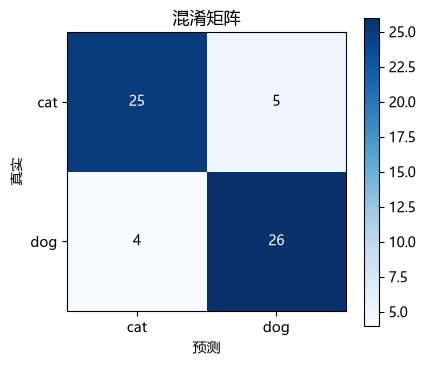

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

all_pred, all_label = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in val_loader:
        logits = model(imgs.to(device))
        all_pred += logits.argmax(1).cpu().tolist()
        all_label += labels.tolist()

acc = sum(p == t for p, t in zip(all_pred, all_label)) / len(all_label)
print(f'验证集准确率: {acc:.4f}')
print(classification_report(all_label, all_pred, target_names=classes, digits=4))

cm = confusion_matrix(all_label, all_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(2)); ax.set_yticks(range(2))
ax.set_xticklabels(classes); ax.set_yticklabels(classes)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('预测'); ax.set_ylabel('真实')
ax.set_title('混淆矩阵')
plt.colorbar(im)
plt.show()

## 5. 预测：对一张新图输出概率

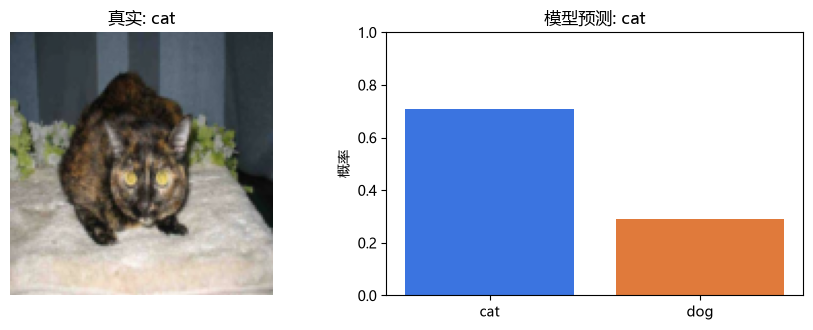

In [7]:
img, true_label = val_set[5]
with torch.no_grad():
    probs = F.softmax(model(img.unsqueeze(0).to(device)), dim=1)[0].cpu()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
ax1.imshow(denorm(img).permute(1, 2, 0).numpy())
ax1.set_title(f'真实: {classes[true_label]}')
ax1.axis('off')
ax2.bar(classes, probs.numpy(), color=['#3b74e0', '#e07a3b'])
ax2.set_ylim(0, 1); ax2.set_ylabel('概率'); ax2.set_title('模型预测')
pred = classes[probs.argmax().item()]
ax2.set_title(f'模型预测: {pred}')
plt.tight_layout()
plt.show()

## 6. 特征可视化：ResNet 各层到底学到了什么

用 forward hook 把网络中间层的输出抓出来看看。**低层**（layer1）学到的基本是边缘、颜色、纹理这些“零件”；**高层**（layer3）才开始出现猫/狗的整体轮廓。卷积网络就是这么一层层从细节拼出语义——预训练权重已经会“看”了，所以迁移学习才又快又稳。

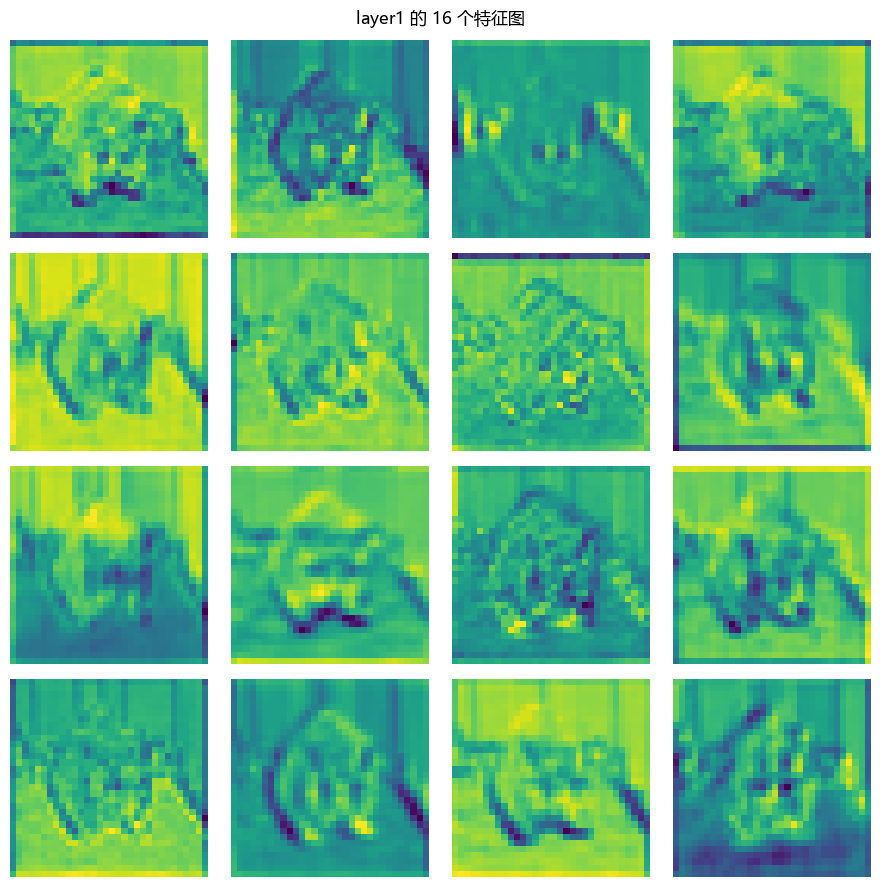

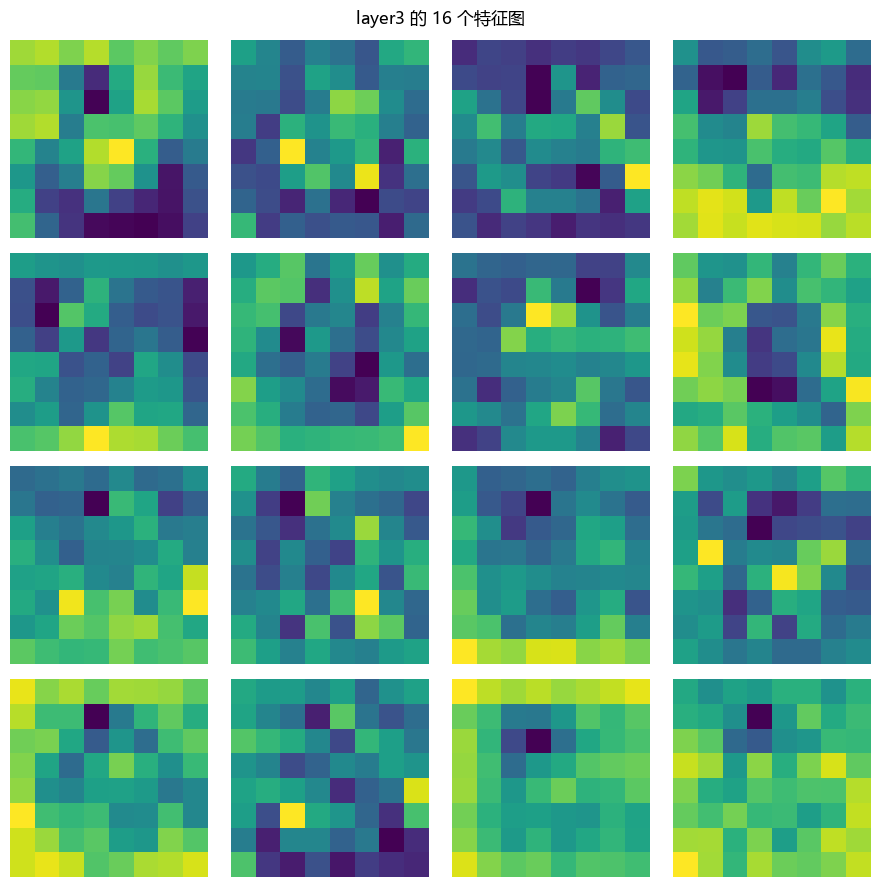

In [8]:
feature_maps = {}


def hook_fn(name):
    def fn(module, inp, out):
        feature_maps[name] = out.detach()
    return fn


model.layer1[0].conv1.register_forward_hook(hook_fn('layer1'))  # 低层：边缘/纹理
model.layer3[0].conv1.register_forward_hook(hook_fn('layer3'))  # 高层：语义形状

with torch.no_grad():
    model(img.unsqueeze(0).to(device))


def plot_feature_maps(name, n=16):
    feats = feature_maps[name][0]  # (C, H, W)
    feats = (feats - feats.min()) / (feats.max() - feats.min() + 1e-8)
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))
    for ax, k in zip(axes.flat, range(n)):
        ax.imshow(feats[k].cpu().numpy(), cmap='viridis')
        ax.axis('off')
    fig.suptitle(f'{name} 的 16 个特征图')
    plt.tight_layout()
    plt.show()


plot_feature_maps('layer1')
plot_feature_maps('layer3')

## 7. 保存模型

保存后可用项目的 `predict.py` 继续做单张预测（注意 `--checkpoint saved/main_notebook_model.pth`）。

In [9]:
import os
os.makedirs('saved', exist_ok=True)
torch.save({
    'model_name': 'resnet18',
    'state_dict': model.state_dict(),
    'classes': classes,
    'image_size': 128,
    'val_acc': acc,
}, 'saved/main_notebook_model.pth')
print('模型已保存到 saved/main_notebook_model.pth')

模型已保存到 saved/main_notebook_model.pth


## 小结与思考

- 迁移学习只训 8 个 epoch、每类 150 张，验证准确率约 80%-90%（受抽样影响有波动）；
- 特征可视化里能看到：低层学边缘/颜色，高层学“形状/语义”；
- 想再提高：加大数据（`n_per_class=500`）、增加 epoch，或换更深的 ResNet50。